In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler,OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.decomposition import PCA
from sklearn.model_selection import StratifiedKFold,cross_val_score,GridSearchCV
from sklearn.metrics import accuracy_score,precision_score,recall_score,f1_score
from sklearn.metrics import confusion_matrix,classification_report
from scipy.stats import ttest_rel

In [3]:
df = pd.read_csv("telecom_churn.csv")

print(df.head(5))
print(df.shape)
print(df.info())
print(df.describe())
print(df.isnull().sum())

print(df["Churn"].value_counts())
print(df["Churn"].value_counts(normalize=True) * 100)



  Customer_ID   Contract_Type  ... Tech_Support_Enabled Churn
0    CUST0001  Month-to-month  ...                    1     0
1    CUST0002        Two year  ...                    1     1
2    CUST0003        One year  ...                    0     0
3    CUST0004        One year  ...                    1     1
4    CUST0005  Month-to-month  ...                    0     0

[5 rows x 18 columns]
(1000, 18)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 18 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Customer_ID              1000 non-null   object 
 1   Contract_Type            1000 non-null   object 
 2   Internet_Service         1000 non-null   object 
 3   Payment_Method           985 non-null    object 
 4   Support_Plan             1000 non-null   object 
 5   Tenure_Months            1000 non-null   float64
 6   Monthly_Charges          975 non-null    float64
 7

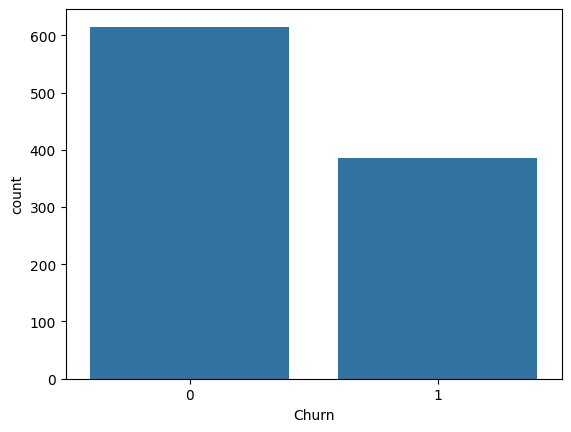

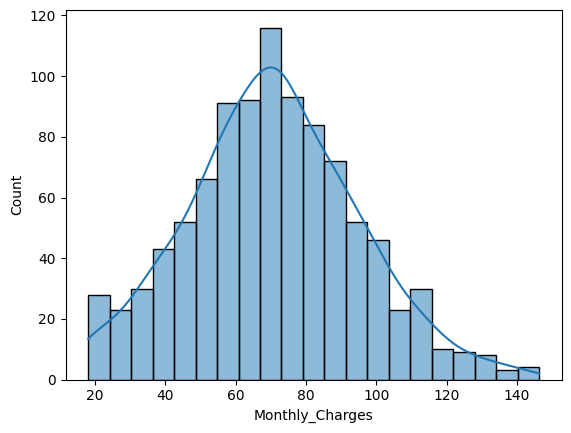

In [7]:
sns.countplot(data=df,x="Churn")
plt.show()

sns.histplot(data=df,x="Monthly_Charges",kde=True)
plt.show()



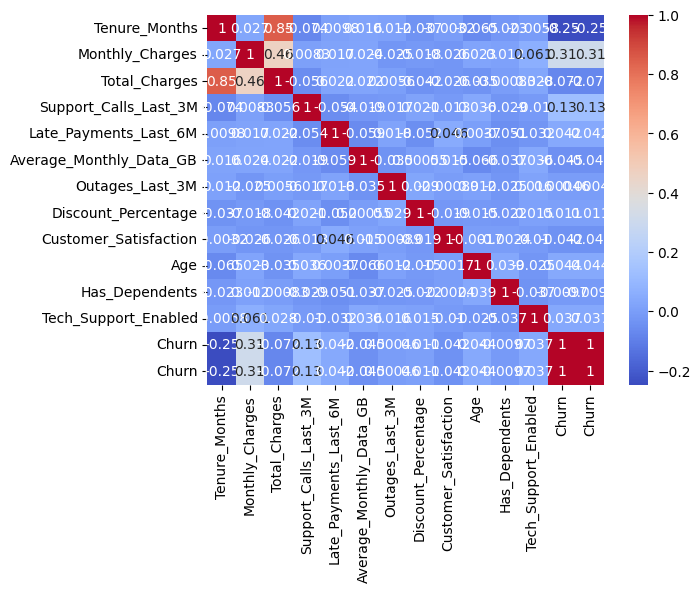

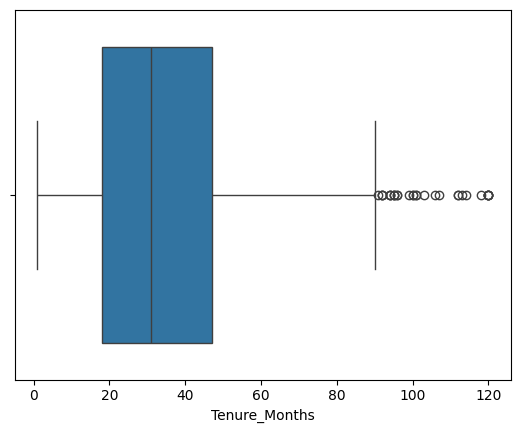

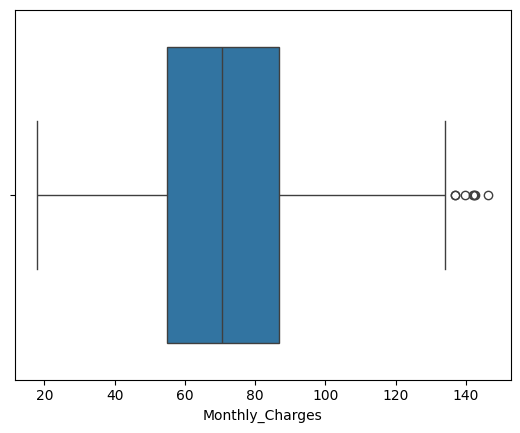

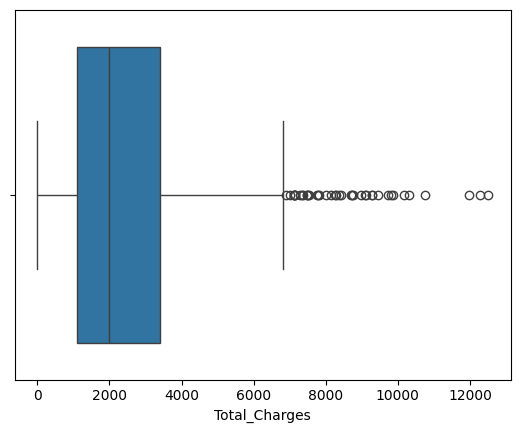

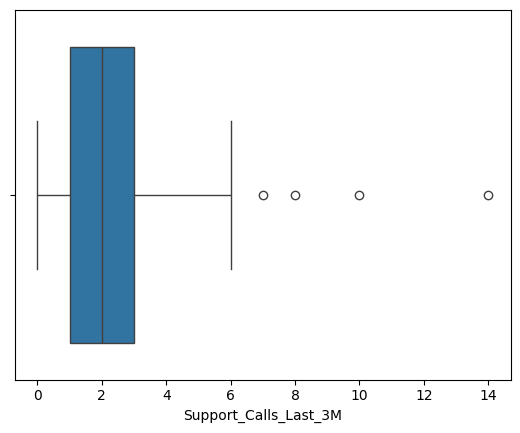

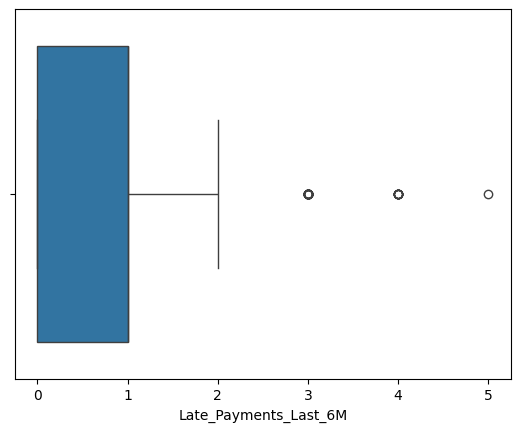

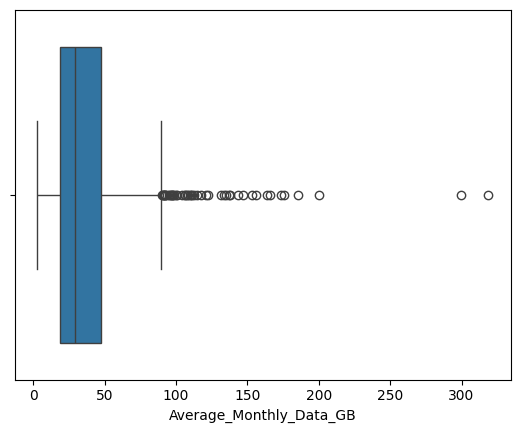

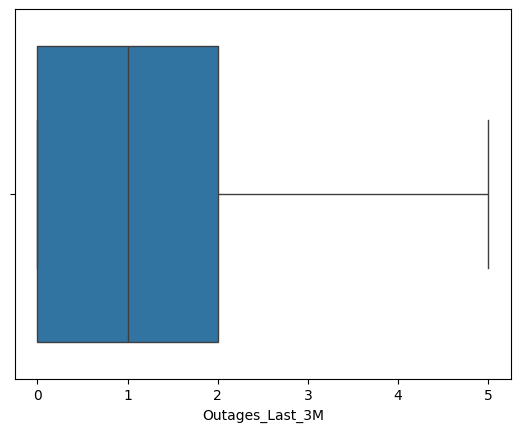

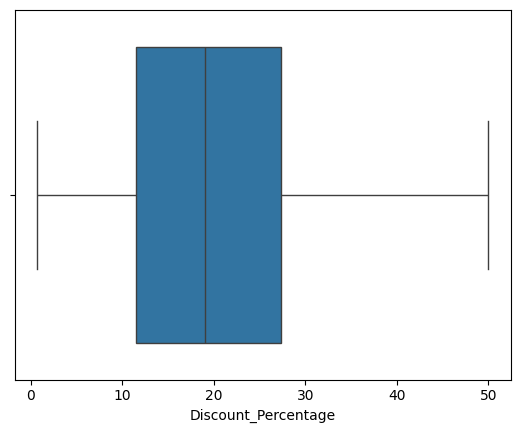

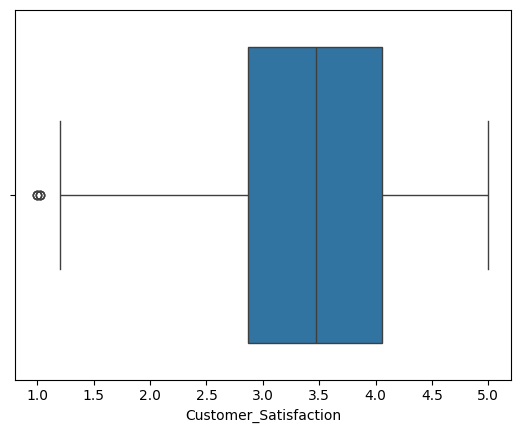

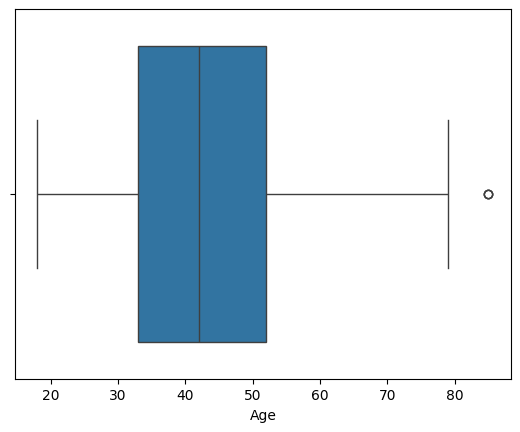

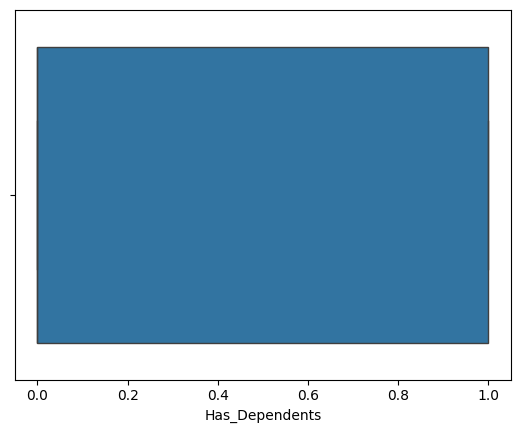

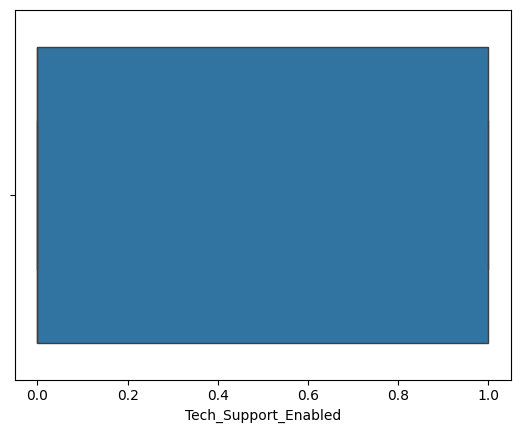

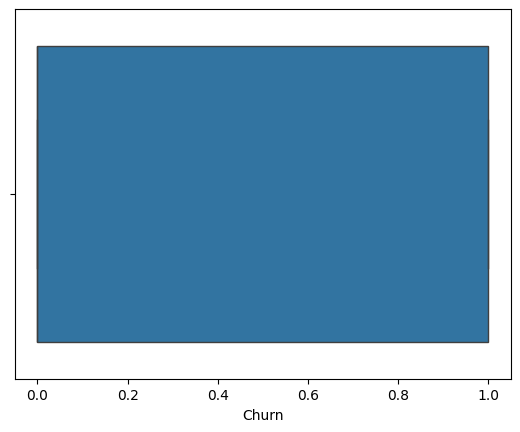

In [11]:
target = "Churn"

summa = df.select_dtypes(include=np.number).columns.tolist()
#cat_cols = df.select_dtypes(exclude=np.number).columns.tolist()

sns.heatmap(df[summa+[target]].corr(numeric_only=True),annot=True,cmap="coolwarm")
plt.show()

for col in summa:
  sns.boxplot(x=df[col])
  plt.show()

In [20]:
df = df.drop_duplicates().reset_index(drop=True)

# Drop Customer_ID as it is a unique identifier with no predictive value
x = df.drop(columns=[target, 'Customer_ID'])
y = df[target]

num_cols = x.select_dtypes(include=np.number).columns.tolist()
cat_cols = x.select_dtypes(exclude=np.number).columns.tolist()

print("Numerical columns:", num_cols)
print("Categorical columns:", cat_cols)
print("X shape:", x.shape)
print("y shape:", y.shape)

Numerical columns: ['Tenure_Months', 'Monthly_Charges', 'Total_Charges', 'Support_Calls_Last_3M', 'Late_Payments_Last_6M', 'Average_Monthly_Data_GB', 'Outages_Last_3M', 'Discount_Percentage', 'Customer_Satisfaction', 'Age', 'Has_Dependents', 'Tech_Support_Enabled']
Categorical columns: ['Contract_Type', 'Internet_Service', 'Payment_Method', 'Support_Plan']
X shape: (1000, 16)
y shape: (1000,)


In [21]:
num_pipe = Pipeline([
    ("impute", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Set sparse_output=False so PCA receives a dense matrix
cat_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(sparse_output=False, handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", num_pipe, num_cols),
    ("cat", cat_pipe, cat_cols)
])
print("preprocessor is set!")

preprocessor is set!


In [25]:
model_without_pca = Pipeline([
    ("preprocessor",preprocessor),
    ("knn",KNeighborsClassifier())
])

param_grid = {
    "knn__n_neighbors":[3,5,7],
    "knn__weights":["uniform","distance"],
    "knn__p":[1,2]
}

cv = StratifiedKFold(n_splits=5,shuffle=True,random_state=42)

grid_without_pca = GridSearchCV(estimator=model_without_pca,param_grid=param_grid,cv=cv,scoring="accuracy",n_jobs=-1)
grid_without_pca.fit(x,y)

print(grid_without_pca.best_params_,grid_without_pca.best_score_)

best_without_pca = grid_without_pca.best_estimator_


{'knn__n_neighbors': 5, 'knn__p': 2, 'knn__weights': 'uniform'} 0.627


In [26]:
model_with_pca = Pipeline([
    ("preprocessor", preprocessor),
    ("pca", PCA(n_components=0.95)),
    ("knn", KNeighborsClassifier())
])

param_grid = {
    "knn__n_neighbors": [3, 5, 7],
    "knn__weights": ["uniform", "distance"],
    "knn__p": [1, 2]
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

grid_with_pca = GridSearchCV(estimator=model_with_pca, param_grid=param_grid, cv=cv, scoring="accuracy", n_jobs=-1)
grid_with_pca.fit(x, y)

print(grid_with_pca.best_params_, grid_with_pca.best_score_)
best_with_pca = grid_with_pca.best_estimator_

{'knn__n_neighbors': 3, 'knn__p': 2, 'knn__weights': 'uniform'} 0.6279999999999999


In [32]:
pca_fitted = best_with_pca.named_steps["pca"]

print(pca_fitted.n_components_)

preprocessor_fitted = best_with_pca.named_steps["preprocessor"]
print(preprocessor_fitted.transform(x).shape[1])

print(pca_fitted.n_components_)

17
25
17


In [35]:
acc_without_pca = cross_val_score(best_without_pca,x,y,cv=cv,scoring="accuracy")
acc_with_pca = cross_val_score(best_with_pca,x,y,cv=cv,scoring="accuracy")

f1_without_pca = cross_val_score(best_without_pca,x,y,cv=cv,scoring="f1")
f1_with_pca = cross_val_score(best_with_pca,x,y,cv=cv,scoring="f1")

print(acc_without_pca,acc_without_pca.mean(),acc_without_pca.std())
print(acc_with_pca,acc_with_pca.mean(),acc_with_pca.std())

print(f1_without_pca,f1_without_pca.mean(),f1_without_pca.std())
print(f1_with_pca,f1_with_pca.mean(),f1_with_pca.std())

[0.625 0.67  0.635 0.6   0.605] 0.627 0.02501999200639363
[0.64  0.675 0.605 0.61  0.61 ] 0.6279999999999999 0.026570660511172867
[0.45255474 0.52857143 0.52287582 0.42028986 0.47682119] 0.48022260744317685 0.041293873301609794
[0.5        0.5112782  0.49032258 0.42647059 0.48684211] 0.48298269392646703 0.029504613867052065


In [36]:
y_pred_nopca = best_with_pca.predict(x)
y_pred_pca = best_with_pca.predict(x)

print(classification_report(y,y_pred_nopca,zero_division=0))
print(classification_report(y,y_pred_pca,zero_division=0))

print(confusion_matrix(y,y_pred_nopca))
print(confusion_matrix(y,y_pred_pca))



              precision    recall  f1-score   support

           0       0.82      0.88      0.85       615
           1       0.78      0.70      0.74       385

    accuracy                           0.81      1000
   macro avg       0.80      0.79      0.79      1000
weighted avg       0.81      0.81      0.81      1000

              precision    recall  f1-score   support

           0       0.82      0.88      0.85       615
           1       0.78      0.70      0.74       385

    accuracy                           0.81      1000
   macro avg       0.80      0.79      0.79      1000
weighted avg       0.81      0.81      0.81      1000

[[539  76]
 [115 270]]
[[539  76]
 [115 270]]


In [37]:
t_stat,p_val = ttest_rel(f1_without_pca,f1_with_pca)
print(t_stat,p_val)

if p_val < 0.05:
  print("Reject the null hypothesis")
else:
  print("Fail to reject the null hypothesis")

-0.20264233509512633 0.8493045871533279
Fail to reject the null hypothesis
